# Missing Value Handling
### What Are Missing Values?
Missing values are data points that are not available or recorded in a dataset.

In simple words, missing values mean some information is absent from the dataset.

#### Example:

In [1]:
import pandas as pd
import numpy as np

data = {
    'Employee': ['Arun', 'Kumar', 'Priya', 'Ravi', 'Divya'],
    'Age': [25, np.nan, 28, 35, 30],
    'Salary': [25000, 30000, np.nan, 40000, 35000],
    'Experience': [2, 3, 4, np.nan, 5]
}

df = pd.DataFrame(data)

print("Employee Dataset:")
display(df)

Employee Dataset:


,Employee,Age,Salary,Experience
0,Arun,25.0,25000.0,2.0
1,Kumar,NaN,30000.0,3.0
2,Priya,28.0,NaN,4.0
3,Ravi,35.0,40000.0,NaN
4,Divya,30.0,35000.0,5.0


## Why Do Missing Values Occur?
Missing values can occur for several reasons.

#### Common reasons:
1. Users skip optional form fields.
2. Data collection errors.
3. Sensor or device failures.
4. Database problems.
5. Incorrect file imports.
6. Information is unavailable.
7. Data is not applicable to a particular person.
##### Example:

An online shopping website collects:
- Customer name
- Age
- Email
- Phone number
- Purchase amount
Some customers may not provide their phone numbers. Therefore, the phone number column contains missing values.

#### Example:

In [2]:
data = {
    'Customer': ['Arun', 'Kumar', 'Priya', 'Ravi'],
    'Age': [25, 30, np.nan, 35],
    'Phone': ['9876543210', None, '9876543212', None]
}

df = pd.DataFrame(data)

print(df)

print("\nMissing Values:")
print(df.isnull().sum())

  Customer   Age       Phone
0     Arun  25.0  9876543210
1    Kumar  30.0         NaN
2    Priya   NaN  9876543212
3     Ravi  35.0         NaN

Missing Values:
Customer    0
Age         1
Phone       2
dtype: int64


## Types of Missing Data
There are three important statistical categories of missing data.
### MCAR – Missing Completely At Random
MCAR means the probability of a value being missing is unrelated to any observed or unobserved data.

In simple words, data is missing completely by chance.

#### Example:

A computer system suddenly crashes while collecting employee salary information. Some salary values are lost randomly.

In [3]:
data = {
    'Age': [25, 30, np.nan, 35, 40],
    'Salary': [20000, np.nan, 30000, 35000, 40000]
}

df = pd.DataFrame(data)

print(df)

    Age   Salary
0  25.0  20000.0
1  30.0      NaN
2   NaN  30000.0
3  35.0  35000.0
4  40.0  40000.0


### MAR – Missing At Random
MAR means missingness depends on other observed information in the dataset, rather than the missing value itself after accounting for those observed variables.

#### Example:

Suppose older employees are less likely to complete an online salary survey.

Their age is available, but some salary values are missing.

In [4]:
data = {
    'Age': [25, 30, 35, 40, 45],
    'Salary': [20000, 25000, np.nan, np.nan, np.nan]
}

df = pd.DataFrame(data)

print(df)

   Age   Salary
0   25  20000.0
1   30  25000.0
2   35      NaN
3   40      NaN
4   45      NaN


## MNAR – Missing Not At Random
MNAR means the probability of missingness depends on the missing value itself or other unobserved information.

#### Example:

In a salary survey, employees with very high salaries may be less willing to disclose their salary.

In [5]:
data = {
    'Employee': ['A', 'B', 'C', 'D', 'E'],
    'Salary': [20000, 25000, np.nan, np.nan, 30000]
}

df = pd.DataFrame(data)

print(df)

  Employee   Salary
0        A  20000.0
1        B  25000.0
2        C      NaN
3        D      NaN
4        E  30000.0


## Detecting Missing Values
Before handling missing values, we must identify where they occur.

Pandas provides several useful methods.

Method 1: isnull()

In [6]:
print(df.isnull())

   Employee  Salary
0     False   False
1     False   False
2     False    True
3     False    True
4     False   False


#### Method 2: notnull()

In [7]:
print(df.notnull())

   Employee  Salary
0      True    True
1      True    True
2      True   False
3      True   False
4      True    True


#### Method 3: isna()

In [8]:
print(df.isna())

   Employee  Salary
0     False   False
1     False   False
2     False    True
3     False    True
4     False   False


#### Method 4: Count missing values

In [9]:
print(df.isnull().sum())

Employee    0
Salary      2
dtype: int64


#### Method 5: Total missing values

In [10]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 2


## Missing Value Percentage
Missing Value Percentage tells us how much information is missing from each column.

#### Formula:
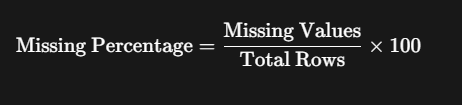
#### Example:

In [11]:
missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().mean() * 100
)

missing_report = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': missing_percentage
})

print("Missing Value Report:")
display(missing_report)

Missing Value Report:


,Missing Count,Missing Percentage
Employee,0,0.0
Salary,2,40.0


## Dropping Rows
Dropping Rows means removing complete records that contain missing values.

Pandas function: dropna()

#### Example:

In [12]:
data = {
    'Name': ['Arun', 'Kumar', 'Priya', 'Ravi'],
    'Age': [25, np.nan, 28, 35],
    'Salary': [20000, 30000, np.nan, 40000]
}

df = pd.DataFrame(data)

print("Before Dropping:")
display(df)

df_clean = df.dropna()

print("\nAfter Dropping:")
display(df_clean)

Before Dropping:


,Name,Age,Salary
0,Arun,25.0,20000.0
1,Kumar,NaN,30000.0
2,Priya,28.0,NaN
3,Ravi,35.0,40000.0



After Dropping:


,Name,Age,Salary
0,Arun,25.0,20000.0
3,Ravi,35.0,40000.0


## Dropping Columns
Dropping Columns means removing an entire column when too much information is missing or the feature is not useful.

Pandas function: drop()

#### Example:

In [13]:
data = {
    'Name': ['Arun', 'Kumar', 'Priya', 'Ravi'],
    'Age': [25, 30, 28, 35],
    'Salary': [20000, np.nan, np.nan, np.nan],
    'City': ['Chennai', 'Madurai', 'Salem', 'Coimbatore']
}

df = pd.DataFrame(data)

print("Before Dropping:")
display(df)

df_clean = df.drop(columns=['Salary'])

print("\nAfter Dropping Salary Column:")
display(df_clean)

Before Dropping:


,Name,Age,Salary,City
0,Arun,25,20000.0,Chennai
1,Kumar,30,NaN,Madurai
2,Priya,28,NaN,Salem
3,Ravi,35,NaN,Coimbatore



After Dropping Salary Column:


,Name,Age,City
0,Arun,25,Chennai
1,Kumar,30,Madurai
2,Priya,28,Salem
3,Ravi,35,Coimbatore


## Mean Imputation
Mean Imputation means replacing missing numerical values with the average of available values.

#### Formula:
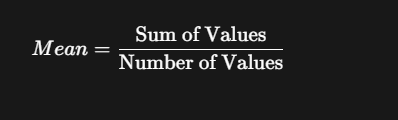

#### Example:

In [14]:
data = {
    'Age': [25, 30, 35, np.nan, 40]
}

df = pd.DataFrame(data)

print("Before Imputation:")
display(df)

mean_value = df['Age'].mean()

df['Age'] = df['Age'].fillna(mean_value)

print("\nMean Value:", mean_value)

print("\nAfter Mean Imputation:")
display(df)

Before Imputation:


,Age
0,25.0
1,30.0
2,35.0
3,NaN
4,40.0



Mean Value: 32.5

After Mean Imputation:


,Age
0,25.0
1,30.0
2,35.0
3,32.5
4,40.0


## Median Imputation
Median Imputation means replacing missing numerical values with the middle value of the available observations.

#### Example:

Age values:

20, 25, 30, 35, Missing

Median = 27.5.

In [15]:
data = {
    'Salary': [20000, 25000, 30000, 35000, 500000, np.nan]
}

df = pd.DataFrame(data)

print("Mean:", df['Salary'].mean())

print("Median:", df['Salary'].median())

Mean: 122000.0
Median: 30000.0


## Mode Imputation
Mode Imputation means replacing missing values with the most frequently occurring value.

It is commonly used for categorical data.

#### Example:

Department:

IT, HR, IT, Finance, Missing

Mode = IT.

In [16]:
data = {
    'Department': [
        'IT', 'HR', 'IT', 'Finance', np.nan
    ]
}

df = pd.DataFrame(data)

mode_value = df['Department'].mode()[0]

df['Department'] = df['Department'].fillna(mode_value)

print("Mode Value:", mode_value)

print("\nAfter Mode Imputation:")
display(df)

Mode Value: IT

After Mode Imputation:


,Department
0,IT
1,HR
2,IT
3,Finance
4,IT


## Constant Value Imputation
Constant Value Imputation means replacing missing values with a predefined value.

#### Examples:
- Age → 0 (only if zero has a valid interpretation).
- Department → Unknown.
- City → Not Provided.
- Salary → -1 (only if the downstream system explicitly supports this sentinel).

In [17]:
data = {
    'Name': ['Arun', 'Kumar', 'Priya', 'Ravi'],
    'Age': [25, np.nan, 28, 35],
    'Department': ['IT', np.nan, 'HR', 'Finance']
}

df = pd.DataFrame(data)

print("Before:")
display(df)

df['Age'] = df['Age'].fillna(-1)

df['Department'] = df['Department'].fillna('Unknown')

print("\nAfter Constant Imputation:")
display(df)

Before:


,Name,Age,Department
0,Arun,25.0,IT
1,Kumar,NaN,NaN
2,Priya,28.0,HR
3,Ravi,35.0,Finance



After Constant Imputation:


,Name,Age,Department
0,Arun,25.0,IT
1,Kumar,-1.0,Unknown
2,Priya,28.0,HR
3,Ravi,35.0,Finance


## Forward Fill
Forward Fill means replacing a missing value with the previous available value.

Pandas function: ffill().

### Example:

In [18]:
data = {
    'Day': ['Monday', 'Tuesday', 'Wednesday', 'Thursday'],
    'Temperature': [30, np.nan, 32, np.nan]
}

df = pd.DataFrame(data)

df['Temperature'] = df['Temperature'].ffill()

print(df)

         Day  Temperature
0     Monday         30.0
1    Tuesday         30.0
2  Wednesday         32.0
3   Thursday         32.0


## Backward Fill
Backward Fill means replacing missing values with the next available value.

Pandas function: bfill().

#### Example:

In [19]:
data = {
    'Day': ['Monday', 'Tuesday', 'Wednesday', 'Thursday'],
    'Temperature': [np.nan, 30, np.nan, 32]
}

df = pd.DataFrame(data)

df['Temperature'] = df['Temperature'].bfill()

print(df)

         Day  Temperature
0     Monday         30.0
1    Tuesday         30.0
2  Wednesday         32.0
3   Thursday         32.0


## Interpolation
Interpolation estimates missing values using surrounding observations.

It is useful when values follow a reasonably continuous pattern.

#### Example:

In [20]:
data = {
    'Day': [1, 2, 3, 4, 5],
    'Temperature': [20, np.nan, 30, np.nan, 40]
}

df = pd.DataFrame(data)

df['Temperature'] = df['Temperature'].interpolate(
    method='linear'
)

print(df)

   Day  Temperature
0    1         20.0
1    2         25.0
2    3         30.0
3    4         35.0
4    5         40.0


## Group-Based Imputation
Group-Based Imputation means replacing missing values using statistics calculated within relevant groups.

#### Example:

In [21]:
data = {
    'Employee': ['Arun', 'Kumar', 'Priya', 'Ravi'],
    'Department': ['IT', 'IT', 'HR', 'HR'],
    'Salary': [30000, np.nan, 25000, np.nan]
}

df = pd.DataFrame(data)

print("Before:")
display(df)

df['Salary'] = df['Salary'].fillna(
    df.groupby('Department')['Salary']
      .transform('median')
)

print("\nAfter Group-Based Imputation:")
display(df)

Before:


,Employee,Department,Salary
0,Arun,IT,30000.0
1,Kumar,IT,NaN
2,Priya,HR,25000.0
3,Ravi,HR,NaN



After Group-Based Imputation:


,Employee,Department,Salary
0,Arun,IT,30000.0
1,Kumar,IT,30000.0
2,Priya,HR,25000.0
3,Ravi,HR,25000.0


## KNN Imputation
KNN means K-Nearest Neighbors.

KNN Imputation replaces missing values using information from similar records.

In simple words:

It finds the most similar rows and uses their available values to estimate the missing value.

#### Example:

In [22]:
import pandas as pd
import numpy as np

from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

data = {
    'Age': [25, 30, np.nan, 35, 40],
    'Salary': [20000, 30000, 35000, np.nan, 45000],
    'Experience': [1, 3, 5, 7, 9]
}

df = pd.DataFrame(data)

print("Before KNN Imputation:")
display(df)

# Scale the features before distance-based imputation
scaler = StandardScaler()

scaled_data = scaler.fit_transform(df)

# KNN imputation
knn_imputer = KNNImputer(n_neighbors=2)

imputed_data = knn_imputer.fit_transform(scaled_data)

# Convert values back to original scale
result = pd.DataFrame(
    scaler.inverse_transform(imputed_data),
    columns=df.columns
)

print("\nAfter KNN Imputation:")
display(result)

Before KNN Imputation:


,Age,Salary,Experience
0,25.0,20000.0,1
1,30.0,30000.0,3
2,NaN,35000.0,5
3,35.0,NaN,7
4,40.0,45000.0,9



After KNN Imputation:


,Age,Salary,Experience
0,25.0,20000.0,1.0
1,30.0,30000.0,3.0
2,32.5,35000.0,5.0
3,35.0,40000.0,7.0
4,40.0,45000.0,9.0
